# 03 — Attribution vs. Incrementality

**Goal:** show concretely why "conversions the ad platform attributes to the campaign" overstates the campaign's true causal impact, and translate both numbers into a budget decision.

**Naive attribution** (what an ad platform typically reports): every conversion among people who were shown/eligible for the ad gets counted as caused by the ad.

**True incremental effect**: only the *extra* conversions relative to what would have happened without the ad (estimated from the control group) count as caused by the ad.

In [1]:
import sys
sys.path.append('..')
from src.data_loader import load_sample
from src.causal_estimates import compute_itt_lift
from src.cost_assumptions import compute_budget_impact, COST_PER_IMPRESSION, REVENUE_PER_CONVERSION

df = load_sample()
result = compute_itt_lift(df)

naive_attributed_conversions = df.loc[df['treatment'] == 1, 'conversion'].sum()
true_incremental_conversions = result.incremental_conversions

print(f'Naive "attributed" conversions (all treatment-group conversions): {naive_attributed_conversions:,.0f}')
print(f'True incremental conversions (caused by the ad):                   {true_incremental_conversions:,.0f}')
overstatement = naive_attributed_conversions / true_incremental_conversions
print(f'\nNaive attribution overstates the causal impact by {overstatement:.1f}x')

Naive "attributed" conversions (all treatment-group conversions): 3,799
True incremental conversions (caused by the ad):                   1,464

Naive attribution overstates the causal impact by 2.6x


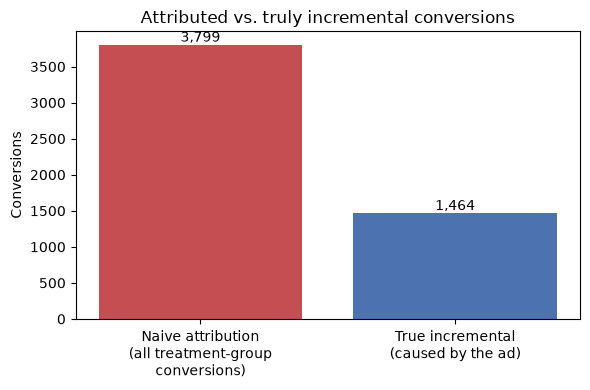

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Naive attribution\n(all treatment-group\nconversions)', 'True incremental\n(caused by the ad)']
values = [naive_attributed_conversions, true_incremental_conversions]
bars = ax.bar(labels, values, color=['#C44E52', '#4C72B0'])
ax.set_ylabel('Conversions')
ax.set_title('Attributed vs. truly incremental conversions')
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:,.0f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Why this matters for a budget decision

Below we apply the (clearly labeled, illustrative) cost/revenue assumptions from `src/cost_assumptions.py` to both numbers. The gap between them is the gap between "the campaign looks profitable" and "the campaign is actually profitable."

In [3]:
print(f'Assumptions: ${COST_PER_IMPRESSION:.2f} cost per impression, '
      f'${REVENUE_PER_CONVERSION:.2f} revenue per conversion (illustrative, not from the dataset)\n')

naive_impact = compute_budget_impact(result.n_treatment, naive_attributed_conversions)
true_impact = compute_budget_impact(result.n_treatment, true_incremental_conversions)

import pandas as pd
pd.DataFrame({
    'Naive (attribution-based)': {
        'Conversions counted': naive_impact.incremental_conversions,
        'Implied revenue ($)': naive_impact.incremental_revenue,
        'Cost per conversion ($)': naive_impact.incremental_cost_per_conversion,
        'ROAS': naive_impact.incremental_roas,
    },
    'True (incremental)': {
        'Conversions counted': true_impact.incremental_conversions,
        'Implied revenue ($)': true_impact.incremental_revenue,
        'Cost per conversion ($)': true_impact.incremental_cost_per_conversion,
        'ROAS': true_impact.incremental_roas,
    },
}).round(2)

Assumptions: $0.01 cost per impression, $45.00 revenue per conversion (illustrative, not from the dataset)



,Naive (attribution-based),True (incremental)
Conversions counted,3799.00,1463.79
Implied revenue ($),170955.00,65870.75
Cost per conversion ($),3.13,8.12
ROAS,14.38,5.54


## Takeaway

Under the naive attribution view, the campaign's reported ROAS looks far more attractive than it actually is: most "attributed" conversions would have happened anyway, so the true incremental ROAS is substantially lower (and the true cost per incremental conversion substantially higher). A marketer evaluating this campaign on attributed conversions alone would systematically over-invest. The incremental figures — not the attributed ones — should drive the spend decision.